# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Tumour-Board Briefing

### Scenario

You are the visualization engineer in the **3-D Imaging Lab at City General Hospital**. Tomorrow morning the
neuro-oncology **tumour board** (a neurosurgeon, a radiologist and an oncologist) will review a patient's head CT
(`unit3_ppt3_head_ct_phantom.csv`). The lab head forwards you four requests:

1. **IT department:** *"The new scanner protocol is 512 × 512 × 300 at 0.5 × 0.5 × 1.0 mm. How much storage per scan,
   and how many samples does one volume-rendered frame cost?"*
2. **Radiologist:** *"Show me the lesion in all three planes, at its centre, with the anatomy undistorted."*
3. **Neurosurgeon:** *"I need the tumour volume in mL — and I want to know how much that number depends on the
   threshold you picked."*
4. **Oncologist:** *"Your last 3-D render showed a beautiful skull and nothing else. I need to see the tumour and its
   relation to the ventricles."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer in your
own words. The ground-truth `labels` array may be used **only to evaluate** your results, never to find the tumour.

## Part 0 — Setup (given)

Run this cell as-is. It loads the volume `vol[z, y, x]`, the evaluation-only `labels`, the voxel spacing, and two
helpers: `make_tf(points)` builds a transfer function from `(hu, (r, g, b), alpha)` control points, and
`render(volume, tf, axis)` ray-casts the volume with front-to-back compositing (resampled at 2× density).

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

ct = pd.read_csv("unit3_ppt3_head_ct_phantom.csv")
NZ, NY, NX = ct.z.max() + 1, ct.y.max() + 1, ct.x.max() + 1
vol = ct.intensity_hu.values.reshape(NZ, NY, NX)        # V[z, y, x]  (z = feet->head, y = front->back, x = left->right)
labels = ct.label.values.reshape(NZ, NY, NX)            # ground truth: 0 air, 1 scalp, 2 bone, 3 brain, 4 CSF, 5 tumour
SPACING = (4.0, 3.0, 3.0)                               # voxel size in mm along (z, y, x)
VOXEL_MM3 = np.prod(SPACING)
ASPECT = SPACING[0] / SPACING[2]                        # use when z is on a screen axis

def make_tf(points):
    # points: list of (hu, (r, g, b), alpha) control points -> transfer function T(s) -> (C, alpha)
    hu = np.array([p[0] for p in points], float)
    rgb = np.array([p[1] for p in points], float)
    alpha = np.array([p[2] for p in points], float)
    def tf(s):
        c = np.stack([np.interp(s, hu, rgb[:, k]) for k in range(3)], axis=-1)
        return c, np.interp(s, hu, alpha)
    return tf

def render(volume, tf, axis=1, upsample=2):
    # Orthographic ray casting with front-to-back compositing; rays travel along `axis`.
    # upsample=2 resamples the volume trilinearly at twice the density (smoother, fewer aliasing artifacts).
    v = ndimage.zoom(volume.astype(float), upsample, order=1) if upsample > 1 else volume
    v = np.moveaxis(v, axis, 0)
    C = np.zeros(v.shape[1:] + (3,)); A = np.zeros(v.shape[1:])
    for sample in v:                                    # one sample per voxel step along every ray at once
        c, a = tf(sample)
        C += ((1 - A) * a)[..., None] * c
        A += (1 - A) * a
    return C, A

print(f"vol {vol.shape} (z, y, x), voxel {SPACING} mm, {VOXEL_MM3:.0f} mm^3 per voxel")

vol (48, 64, 64) (z, y, x), voxel (4.0, 3.0, 3.0) mm, 36 mm^3 per voxel


## Task 1 — The IT Department's Numbers (Request #1)

**Real-world usage:** PACS storage and GPU sizing for 3-D workstations are budgeted from exactly these figures.

**Why this technique:** Voxel count = Nx·Ny·Nz (Slides 7, 12); each ray samples the volume at successive positions
(Slide 22), so one frame costs ≈ rays × samples per ray; early ray termination skips samples once α_acc → 1
(Slide 27).

**TODO:**
1. Number of voxels in a 512 × 512 × 300 scan, and its size in MB at 16 bits per voxel.
2. Physical size of the scanned region in mm, and the volume of one voxel in mm³ (0.5 × 0.5 × 1.0 mm).
3. Samples needed for ONE front-view rendered frame (one ray per x–z pixel, one sample per voxel step in y), and
   for a 360° rotation video of 120 frames.
4. If early ray termination stops rays after 35% of their samples on average, how many samples does the 120-frame
   video need instead?

In [3]:
# TODO 1
nx, ny, nz = 512, 512, 300
n_voxels = nx * ny * nz
scan_mb = n_voxels * 2 / 1024**2                     # 16 bits = 2 bytes per voxel

# TODO 2
dx, dy, dz = 0.5, 0.5, 1.0
extent_mm = (nx * dx, ny * dy, nz * dz)            # (x, y, z) in mm
voxel_mm3 = dx * dy * dz

# TODO 3
rays_per_frame = nx * nz                           # front view: one ray per x-z pixel
samples_per_frame = rays_per_frame * ny            # one sample per voxel step along y
samples_video = samples_per_frame * 120

# TODO 4
samples_video_ert = samples_video * 0.35            # rays stop after 35% of their samples on average

print(f"{n_voxels:,} voxels = {scan_mb:.1f} MB | extent {extent_mm} mm | voxel {voxel_mm3} mm^3")
print(f"samples/frame {samples_per_frame:,} | 120 frames {samples_video:,} | with early termination {samples_video_ert:,.0f}")
print(f"early ray termination saves {samples_video - samples_video_ert:,.0f} samples ({1 - 0.35:.0%})")

78,643,200 voxels = 150.0 MB | extent (256.0, 256.0, 300.0) mm | voxel 0.25 mm^3
samples/frame 78,643,200 | 120 frames 9,437,184,000 | with early termination 3,303,014,400
early ray termination saves 6,134,169,600 samples (65%)


**Reflection:** The new protocol has *anisotropic* voxels (0.5 × 0.5 × 1.0 mm). What two things would go wrong in the
radiologist's coronal and sagittal views if the software ignored that (Slides 8–10)?

_Your answer:_ Both coronal and sagittal views contain the z-axis, where a voxel is 1.0 mm tall but only 0.5 mm wide.
(1) **Geometric distortion:** if each voxel is drawn as a square pixel, the anatomy is squashed to half its true height
along z — a round lesion looks like a flat ellipse, and any distance or angle measured on screen along z is wrong by
a factor of 2. The display must use aspect = dz/dx = 2 (or resample to isotropic voxels). (2) **Resolution
mismatch / staircase artifacts:** detail along z is half as fine as in-plane, so oblique edges in the coronal and
sagittal views show "stair-step" blocks and more partial-volume blurring along z; small structures may be missed
between slices, and interpolation has to be used to fill the gaps.

## Task 2 — Find the Lesion and Show It in Three Planes (Request #2)

**Real-world usage:** Every radiology workstation opens on a 3-plane MPR with linked cross-hairs.

**Why this technique:** **Orthogonal slices / MPR** give complementary views of the same structure (Slides 15–17);
a **window/level** setting is the slice-display transfer function; the correct **voxel aspect ratio** keeps anatomy
undistorted (Slide 9).

**TODO:**
1. Find the lesion *without* `labels`: take voxels with 55 < HU < 90 that lie **inside the brain** — use
   `inside = ndimage.binary_fill_holes(vol > 300) & ~(vol > 300)` and erode it 3 times
   (`ndimage.binary_erosion(..., iterations=3)`) to avoid the partial-volume shell under the skull.
2. Keep the largest connected component (`ndimage.label`) and compute its centroid (z, y, x) as integers.
3. Plot axial, coronal and sagittal slices through that centroid with cross-hairs, a brain window (W = 80, L = 40),
   and `aspect=ASPECT` for the two views that contain z.
4. Evaluation only: print how far (in mm) your centroid is from the centroid of `labels == 5`.

1 candidate component(s); largest = 431 voxels; centroid (z, y, x) = (28, 40, 41)


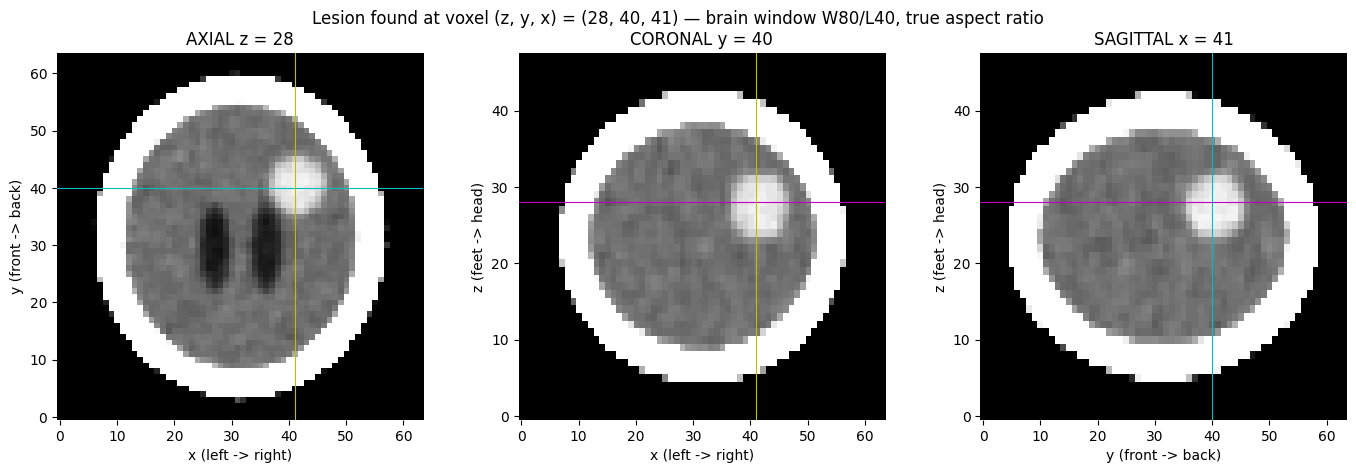

True tumour centroid (z, y, x) = [27.5 40.5 41.5]; my centroid is 2.9 mm away (less than one voxel diagonal = 5.8 mm)


In [4]:
def window(a, W, L):
    return np.clip((a - (L - W / 2)) / W, 0, 1)

# TODO 1
bone = vol > 300
inside = ndimage.binary_fill_holes(bone) & ~bone             # everything enclosed by the skull
inside = ndimage.binary_erosion(inside, iterations=3)        # drop the partial-volume shell under the bone
candidates = (vol > 55) & (vol < 90) & inside

# TODO 2
comp, n_comp = ndimage.label(candidates)
sizes = ndimage.sum(candidates, comp, range(1, n_comp + 1))
lesion = comp == (np.argmax(sizes) + 1)
cz, cy, cx = np.round(np.argwhere(lesion).mean(axis=0)).astype(int)
print(f"{n_comp} candidate component(s); largest = {lesion.sum()} voxels; centroid (z, y, x) = ({cz}, {cy}, {cx})")

# TODO 3
fig, axes = plt.subplots(1, 3, figsize=(14, 4.6))
W, L = 80, 40
axes[0].imshow(window(vol[cz], W, L), cmap="gray", origin="lower", vmin=0, vmax=1)
axes[0].axhline(cy, color="c", lw=0.8); axes[0].axvline(cx, color="y", lw=0.8)
axes[0].set_title(f"AXIAL z = {cz}"); axes[0].set_xlabel("x (left -> right)"); axes[0].set_ylabel("y (front -> back)")
axes[1].imshow(window(vol[:, cy, :], W, L), cmap="gray", origin="lower", vmin=0, vmax=1, aspect=ASPECT)
axes[1].axhline(cz, color="m", lw=0.8); axes[1].axvline(cx, color="y", lw=0.8)
axes[1].set_title(f"CORONAL y = {cy}"); axes[1].set_xlabel("x (left -> right)"); axes[1].set_ylabel("z (feet -> head)")
axes[2].imshow(window(vol[:, :, cx], W, L), cmap="gray", origin="lower", vmin=0, vmax=1, aspect=ASPECT)
axes[2].axhline(cz, color="m", lw=0.8); axes[2].axvline(cy, color="c", lw=0.8)
axes[2].set_title(f"SAGITTAL x = {cx}"); axes[2].set_xlabel("y (front -> back)"); axes[2].set_ylabel("z (feet -> head)")
for ax in axes:
    ax.spines[:].set_visible(False)
plt.suptitle(f"Lesion found at voxel (z, y, x) = ({cz}, {cy}, {cx}) — brain window W{W}/L{L}, true aspect ratio")
plt.tight_layout(); plt.show()

# TODO 4 (evaluation only)
true_c = np.argwhere(labels == 5).mean(axis=0)
err_mm = np.linalg.norm((np.array([cz, cy, cx]) - true_c) * np.array(SPACING))
print(f"True tumour centroid (z, y, x) = {np.round(true_c, 1)}; my centroid is {err_mm:.1f} mm away "
      f"(less than one voxel diagonal = {np.linalg.norm(SPACING):.1f} mm)")

**Reflection:** Why did you need the erosion step? Explain in terms of the **partial-volume effect** and the
overlapping intensity ranges the lecture lists as a transfer-function challenge (Slide 28).

_Your answer:_ A voxel on the boundary between bone (~750 HU) and brain/CSF (~10–40 HU) contains a mixture of both
tissues, so its value is an average that can land anywhere in between — including the 55–90 HU "tumour" range. This
**partial-volume effect** creates a thin shell of tumour-like voxels just inside the skull. Because intensity alone
cannot tell a real tumour voxel (~68 HU) from a bone/brain mixture with the same value — exactly the **overlapping
intensity ranges** problem — a pure threshold picks up both. Eroding the intracranial mask by 3 voxels throws away
that boundary shell using *spatial* information (distance from the skull), which the intensity value does not carry.
Without erosion the same threshold gives hundreds of extra connected components scattered under the skull.

## Task 3 — Tumour Volume and Its Threshold Sensitivity (Request #3)

**Real-world usage:** Tumour volume drives treatment decisions and response assessment, so its uncertainty must be
reported.

**Why this technique:** An **isosurface/segmentation at threshold c** defines the structure — and *the chosen c
strongly influences the resulting geometry* (Slides 19–20, 31–32).

**TODO:**
1. For c in `[45, 50, 55, 60, 65, 70]`, grow the region `vol > c` from your lesion centre (connected component
   containing `(cz, cy, cx)`).
2. For each c, record the voxel count, the volume in mL (`voxels * VOXEL_MM3 / 1000`), and — evaluation only — the
   Dice overlap with `labels == 5`.
3. Plot volume (mL) vs. threshold, and mark the threshold with the best Dice.
4. Print the range of volumes you would report to the surgeon.

,threshold_hu,voxels,volume_ml,dice_vs_truth
0,45,535,19.260,0.929
1,50,464,16.704,0.994
2,55,431,15.516,0.963
3,60,350,12.600,0.860
4,65,273,9.828,0.741
5,70,170,6.120,0.536


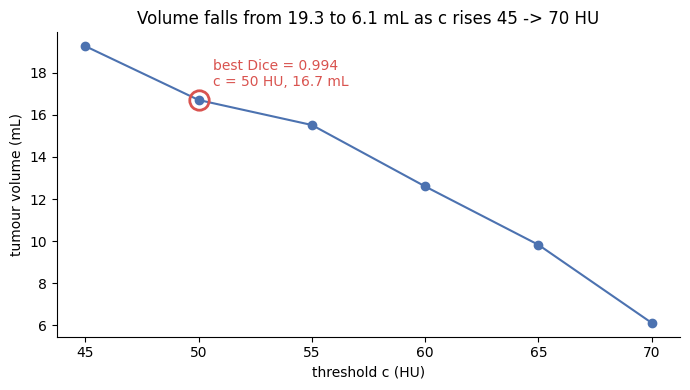

Report to surgeon: tumour volume ≈ 16.7 mL (c = 50 HU), plausible range 12.6–19.3 mL for c = 45–60 HU; full tested range 6.1–19.3 mL.


In [5]:
truth = labels == 5
rows = []
# TODO 1 & 2
thresholds = [45, 50, 55, 60, 65, 70]
regions = {}
for c in thresholds:
    comp_c, _ = ndimage.label(vol > c)
    region = comp_c == comp_c[cz, cy, cx]                # connected component containing the lesion centre
    regions[c] = region
    n = int(region.sum())
    dice = 2 * (region & truth).sum() / (n + truth.sum())   # evaluation only
    rows.append({"threshold_hu": c, "voxels": n, "volume_ml": n * VOXEL_MM3 / 1000, "dice_vs_truth": dice})

table = pd.DataFrame(rows).round(3)
display(table)

# TODO 3
best = table.loc[table.dice_vs_truth.idxmax()]
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(table.threshold_hu, table.volume_ml, "o-", color="#4C72B0")
ax.plot(best.threshold_hu, best.volume_ml, "o", ms=14, mfc="none", mec="#D9534F", mew=2)
ax.annotate(f"best Dice = {best.dice_vs_truth:.3f}\nc = {best.threshold_hu:.0f} HU, {best.volume_ml:.1f} mL",
            (best.threshold_hu, best.volume_ml), xytext=(10, 10), textcoords="offset points", color="#D9534F")
ax.set_xlabel("threshold c (HU)"); ax.set_ylabel("tumour volume (mL)")
ax.set_title(f"Volume falls from {table.volume_ml.max():.1f} to {table.volume_ml.min():.1f} mL as c rises 45 -> 70 HU")
plt.tight_layout(); plt.show()

# TODO 4
plausible = table[(table.threshold_hu >= 45) & (table.threshold_hu <= 60)]   # thresholds between brain (~36) and tumour core (~68)
print(f"Report to surgeon: tumour volume ≈ {best.volume_ml:.1f} mL (c = {best.threshold_hu:.0f} HU), "
      f"plausible range {plausible.volume_ml.min():.1f}–{plausible.volume_ml.max():.1f} mL for c = 45–60 HU; "
      f"full tested range {table.volume_ml.min():.1f}–{table.volume_ml.max():.1f} mL.")

**Reflection:** In real life there is no ground-truth label. How would you choose and justify c for the tumour
board, and how would you *visualize* the uncertainty so the surgeon doesn't treat a single number as exact?

_Your answer:_ I would pick c from the data itself: the intensity histogram (or a profile across the lesion edge)
shows a brain peak (~36 HU) and a tumour peak (~68 HU), and a threshold near the midpoint (~50 HU) is the standard
"half-maximum" choice for the boundary. I would also check that the volume curve is relatively flat around that c
(stable = trustworthy) and ask the radiologist to confirm the contour on several slices. To show uncertainty I
would report a **range** (≈ 12.6–19.3 mL for c = 45–60 HU) instead of one number, plot the volume-vs-threshold curve,
and overlay the contours for several thresholds on the MPR slices (nested inner/outer contours, or a colour band
between the tightest and loosest contour) so the surgeon sees *where* the boundary is uncertain.

## Task 4 — A 3-D Render That Shows the Tumour (Request #4)

**Real-world usage:** Pre-operative 3-D views show a lesion in context with critical structures (here the ventricles).

**Why this technique:** **Direct volume rendering** with a designed **transfer function** — colour to *identify*
materials, opacity to *reveal or suppress* them (Slides 21–27); occlusion is the main enemy (Slide 28).

**TODO:**
1. Render the given `bone_tf` (front view, `axis=1`) — this is the "beautiful skull" the oncologist complained about.
2. Design your own `tumour_tf` with `make_tf([...])` so that: air and soft tissue are fully transparent, bone is
   *almost* transparent (α ≤ 0.01, still gives context), CSF (≈ 5–20 HU) is blue and faint, and the tumour range
   is red. Remember that opacity **accumulates over every sample along a ray**: a thick structure with α ≈ 0.1
   per sample becomes nearly opaque, while a thin one stays faint — use that to your advantage.
3. Render your TF from the front (`axis=1`) **and** from above (`axis=0`), side by side with the bone render.
4. Give the figure a conclusion-style title.

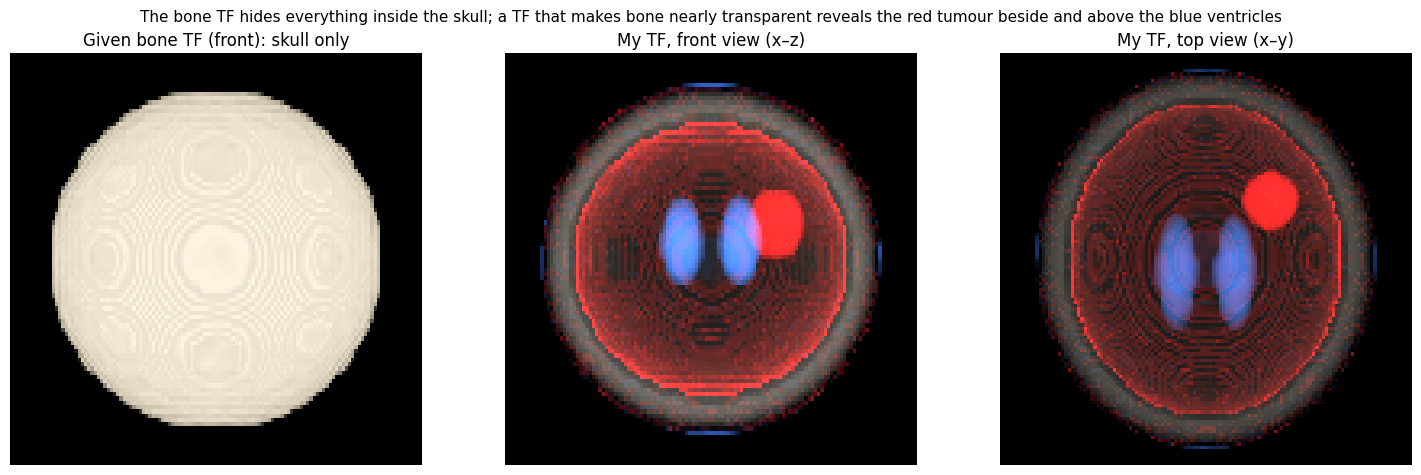

In [6]:
bone_tf = make_tf([(-1000, (0, 0, 0), 0), (200, (0, 0, 0), 0), (400, (1, 0.95, 0.85), 0.3), (1500, (1, 1, 1), 0.6)])

# TODO 2: your transfer function
BLUE, RED, BONE = (0.25, 0.5, 1.0), (1.0, 0.1, 0.1), (1.0, 0.95, 0.85)
tumour_tf = make_tf([
    (-1000, (0, 0, 0), 0.0), (0,   (0, 0, 0), 0.0),      # air, fat, scalp: transparent
    (5,     BLUE, 0.03),     (20,  BLUE, 0.03),           # CSF / ventricles: faint blue
    (26,    BLUE, 0.0),      (55,  RED, 0.0),             # brain (~36 HU): transparent
    (62,    RED, 0.07),      (78,  RED, 0.07),            # tumour core (~68 HU): red; ~18 samples deep -> nearly opaque,
    (85,    RED, 0.0),       (300, BONE, 0.0),            #   while the thin partial-volume shell only reaches a faint tint
    (400,   BONE, 0.004),    (1500, (1, 1, 1), 0.008),    # bone: almost transparent context (alpha <= 0.01)
])

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
# TODO 1 & 3: bone render | your TF front view | your TF top view
C_bone, _ = render(vol, bone_tf, axis=1)
C_front, _ = render(vol, tumour_tf, axis=1)
C_top, _ = render(vol, tumour_tf, axis=0)
axes[0].imshow(np.clip(C_bone, 0, 1), origin="lower", aspect=ASPECT); axes[0].set_title("Given bone TF (front): skull only")
axes[1].imshow(np.clip(C_front * 1.8, 0, 1), origin="lower", aspect=ASPECT); axes[1].set_title("My TF, front view (x–z)")
axes[2].imshow(np.clip(C_top * 1.8, 0, 1), origin="lower"); axes[2].set_title("My TF, top view (x–y)")
for ax in axes: ax.axis("off")

# TODO 4: suptitle
plt.suptitle("The bone TF hides everything inside the skull; a TF that makes bone nearly transparent reveals the red tumour "
             "beside and above the blue ventricles", fontsize=11)
plt.tight_layout(); plt.show()

**Reflection:** Your tumour TF probably also lights up a faint red rim just inside the skull. Which volume-rendering
challenge from Slide 28 causes it? Name one technique from this lecture (hint: Slides 31–32) that would remove it,
and explain why a transfer function alone cannot.

_Your answer:_ The rim comes from **overlapping intensity ranges** caused by the **partial-volume effect**: voxels at the
bone/brain boundary average ~750 HU bone with ~36 HU brain, and some of those mixtures fall exactly in the tumour's
62–78 HU band, so the TF paints them red. (Because the render keeps the shell faint by using a low per-sample α, only
the thick tumour builds up full opacity, but the shell is still visible.) A 1-D transfer function maps **intensity
only** — it cannot distinguish a true 68 HU tumour voxel from a 68 HU bone/brain mixture, because they have the same
value. **Segmentation** (as in Task 2: an eroded intracranial mask + connected-component labelling, i.e. a
region-grown isosurface from the lesion seed) removes it by using *spatial* information — position and connectivity —
and then the renderer colours only the segmented tumour label. (A multi-dimensional TF using gradient magnitude
would also help, since boundary voxels have high gradient while the tumour interior does not.)

## Task 5 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence note to the tumour board covering the whole notebook. It should:
- State where the lesion is and its volume **as a range** (Task 3), in plain language.
- Recommend which **one** view to open the meeting with (MPR, segmentation overlay, or the 3-D render) and justify
  it with at least one lecture idea (occlusion, slicing exposes internal structure, transfer-function overlap,
  segmentation enables measurement).
- Name one limitation of the 3-D render the board should keep in mind.

_Your final note here:_

To the tumour board: the CT shows a single, well-defined, roughly spherical lesion (~68 HU, brighter than brain) in the
upper part of the head, behind the centre and to one side of the midline (image x-side), sitting just beside and
above the lateral ventricles and clearly separate from the skull. Its volume is about **17 mL**, but depending on
where the boundary threshold is drawn (45–60 HU) a reasonable estimate is **about 13–19 mL**, so please read it as a
range, not an exact figure. I recommend opening with the **three-plane MPR with the segmentation contour overlaid**:
slicing exposes the internal structure without occlusion, shows the true boundary against surrounding brain in all
three directions at the correct aspect ratio, and the segmentation is what makes the volume measurement possible. The
3-D render is useful afterwards to show the lesion's relationship to the ventricles at a glance, but keep in mind
that it is a **projection** — depth is ambiguous, and its colours come from a transfer function, so the faint red
rim under the skull is a partial-volume artifact, not tumour, and nothing in the render should be used for
measurement.